# Control modular: pequeña fábrica con averías

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/LCS_modular_control_small_factory.ipynb)

La pequeña fábrica tiene dos máquinas, $M_1$ y $M_2$, unidas por un buffer $B$ de capacidad 2.
Cada máquina puede averiarse mientras trabaja y entonces hay que repararla. Hay dos
especificaciones: el buffer no debe desbordarse ni vaciarse por debajo de cero, y si las dos
máquinas están averiadas se repara primero $M_2$.

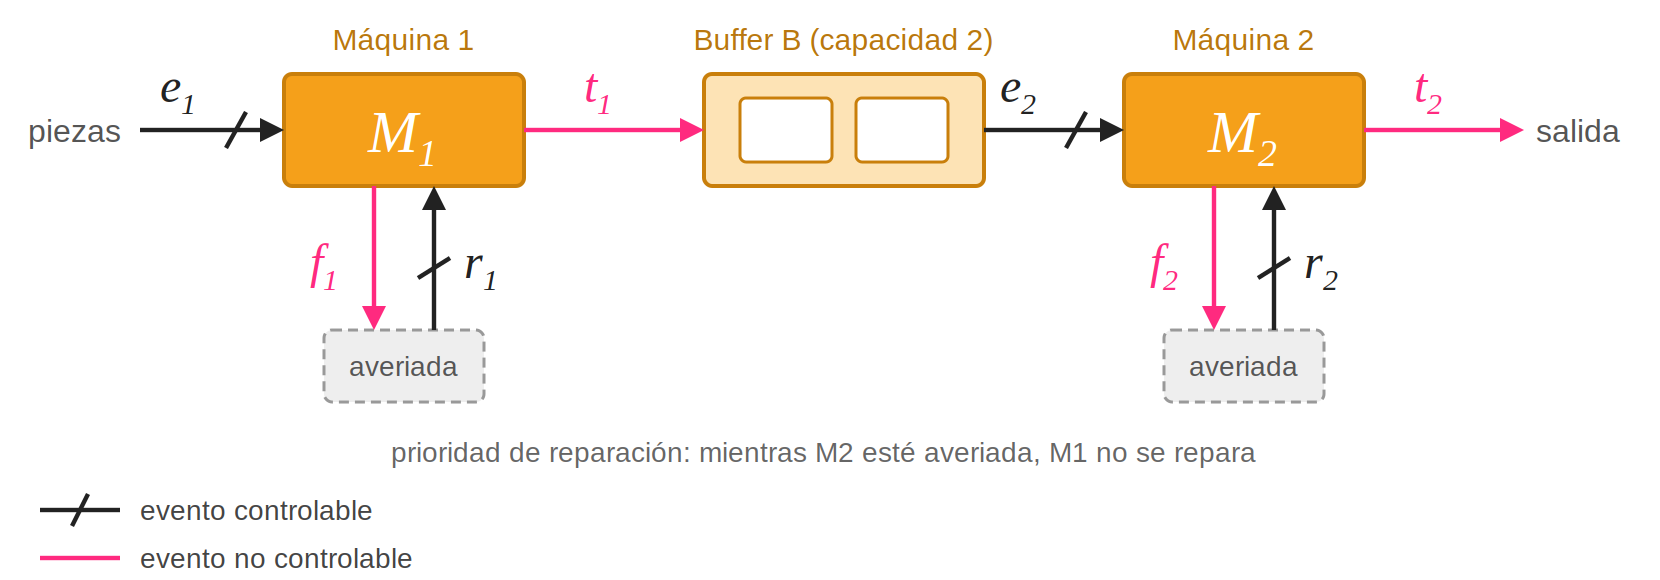

Los eventos controlables se marcan con una rayita sobre el arco y los no controlables van en
color rosado, como en los dibujos de DESlab.

| Evento | Significado | Tipo |
|---|---|---|
| $e_1$ | $M_1$ toma una pieza y empieza a trabajar | controlable |
| $t_1$ | $M_1$ termina y deja la pieza en el buffer $B$ | no controlable |
| $f_1$ | $M_1$ se avería y la pieza no llega al buffer | no controlable |
| $r_1$ | $M_1$ es reparada | controlable |
| $e_2$ | $M_2$ toma una pieza del buffer | controlable |
| $t_2$ | $M_2$ termina y la pieza sale de la fábrica | no controlable |
| $f_2$ | $M_2$ se avería | no controlable |
| $r_2$ | $M_2$ es reparada | controlable |

In [2]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
DESlab instalado desde el commit c9901b1


In [3]:
from deslab import *

## 1. Planta: máquinas $M_1$ y $M_2$

Cada máquina tiene tres estados: $D$ (desocupada, inicial y marcado), $O$ (ocupada) y $C$
(averiada). Los eventos controlables se dan con `Sigcon`; si se omite, DESlab considera todos los
eventos controlables, y la composición paralela une los conjuntos `Sigcon`.

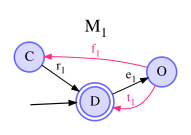

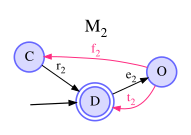

In [4]:
syms('D O C B0 B1 B2 OK KO e1 t1 f1 r1 e2 t2 f2 r2')
tabla = [(e1, 'e_1'), (t1, 't_1'), (f1, 'f_1'), (r1, 'r_1'),
         (e2, 'e_2'), (t2, 't_2'), (f2, 'f_2'), (r2, 'r_2')]

M1 = fsa([D, O, C], [e1, t1, f1, r1], [(D, e1, O), (O, t1, D), (O, f1, C), (C, r1, D)],
         [D], [D], tabla, Sigcon=[e1, r1], name='$M_1$')
M2 = fsa([D, O, C], [e2, t2, f2, r2], [(D, e2, O), (O, t2, D), (O, f2, C), (C, r2, D)],
         [D], [D], tabla, Sigcon=[e2, r2], name='$M_2$')
draw(M1, M2)

## 2. Especificaciones: buffer de capacidad 2 y prioridad de reparación

$E_1$ cuenta las piezas del buffer: $t_1$ pone una pieza y $e_2$ la retira. Como en el estado $B2$
(lleno) no está $t_1$, prohíbe el desborde, y como en $B0$ (vacío) no está $e_2$, prohíbe que $M_2$
arranque sin pieza. Todos sus estados son marcados: el buffer puede quedar con piezas.

$E_2$ da prioridad de reparación a $M_2$: en el estado $OK$ ($M_2$ no está averiada) se puede
reparar $M_1$ ($r_1$), pero después de $f_2$ el estado pasa a $KO$, donde $r_1$ no está, hasta que
se repara $M_2$ ($r_2$).

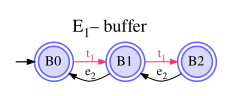

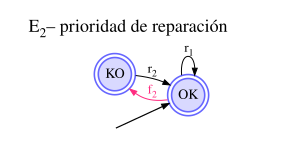

In [5]:
E1 = fsa([B0, B1, B2], [t1, e2], [(B0, t1, B1), (B1, e2, B0), (B1, t1, B2), (B2, e2, B1)],
         [B0], [B0, B1, B2], tabla, Sigcon=[e2], name='$E_1$ -- buffer')
E2 = fsa([OK, KO], [r1, f2, r2], [(OK, r1, OK), (OK, f2, KO), (KO, r2, OK)],
         [OK], [OK, KO], tabla, Sigcon=[r1, r2], name='$E_2$ -- prioridad de reparación')
draw(E1, E2)

## 3. Supervisor monolítico

La planta es $G = M_1 \parallel M_2$. La composición paralela `//` deja libres los eventos que una
especificación no tiene, así que el lenguaje deseado lo marca `G // E1 // E2` y el supervisor
monolítico es `supcontrollable(G // E1 // E2, G)`.

Los estados de la composición paralela son tuplas planas: (estado de $M_1$, de $M_2$, de $B$, de
$E_2$).

estados de G: 9 | estados del supervisor monolítico: 21


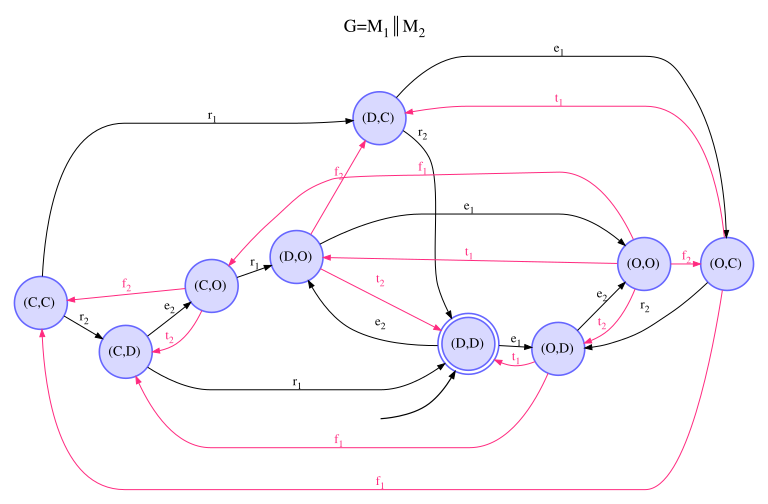

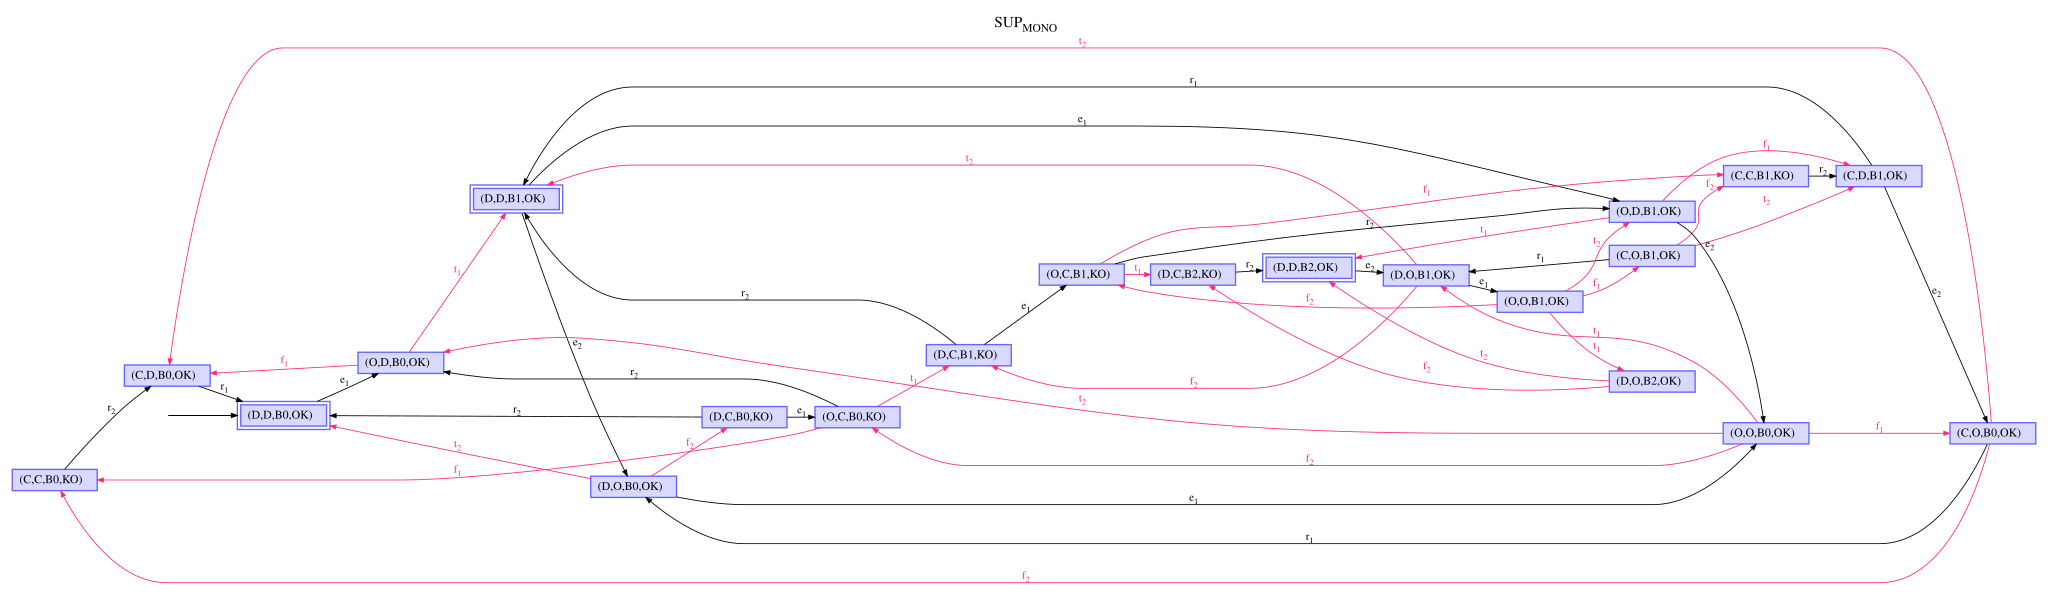

In [6]:
G = (M1 // M2).setpar(name='$G = M_1 \\parallel M_2$')
SUP_MONO = supcontrollable(G // E1 // E2, G)
SUP_MONO = SUP_MONO.setpar(name='$SUP_{MONO}$', style='rectangle')
print('estados de G:', len(G), '| estados del supervisor monolítico:', len(SUP_MONO))
draw(G, SUP_MONO)

El supervisor monolítico no deja que $M_1$ empiece con el buffer lleno, porque al terminar ($t_1$,
no controlable) lo desbordaría, y no deja que $M_2$ arranque con el buffer vacío. Además, cuando
las dos máquinas están averiadas, no repara $M_1$ antes que $M_2$.

## 4. Supervisores modulares

Cada especificación tiene su propio supervisor, calculado con la misma planta $G$.

estados de SUP1: 21 | estados de SUP2: 9
¿SUP1 y SUP2 son controlables? True True


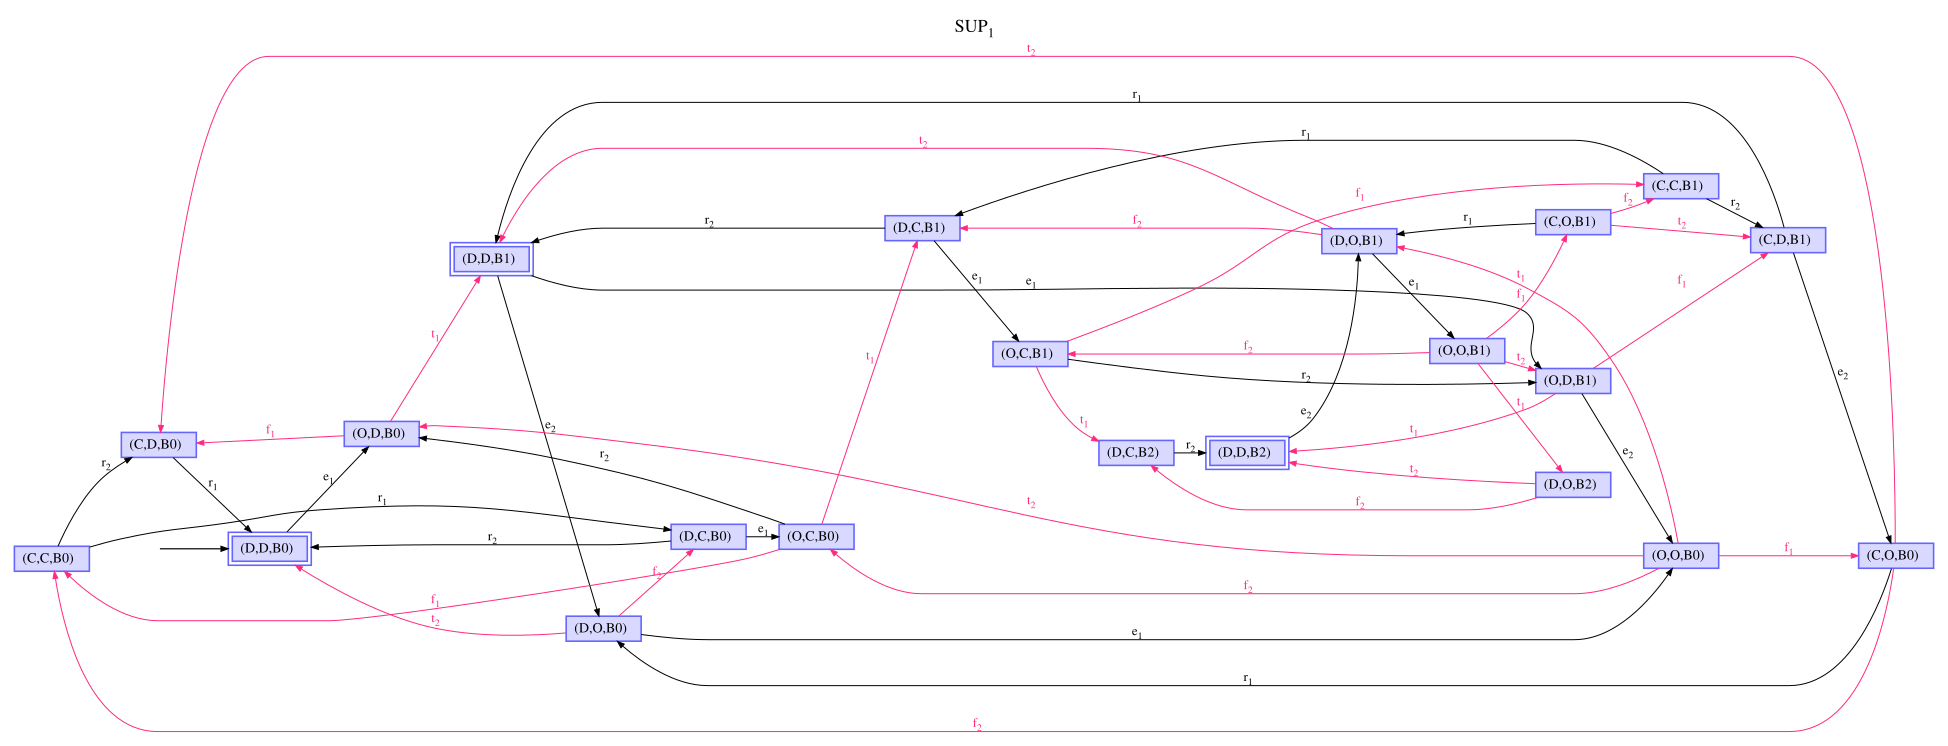

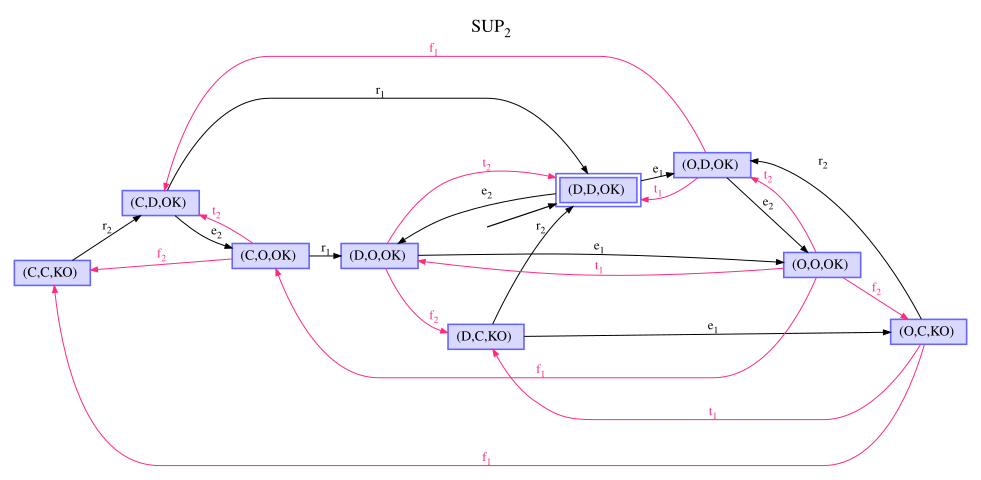

In [7]:
SUP1 = supcontrollable(G // E1, G).setpar(name='$SUP_1$', style='rectangle')
SUP2 = supcontrollable(G // E2, G).setpar(name='$SUP_2$', style='rectangle')
print('estados de SUP1:', len(SUP1), '| estados de SUP2:', len(SUP2))
print('¿SUP1 y SUP2 son controlables?', iscontrollable(SUP1, G), iscontrollable(SUP2, G))
draw(SUP1, SUP2)

## 5. ¿Es el supervisor modular igual al monolítico?

Los dos supervisores actúan a la vez, así que el supervisor total es $SUP_1 \parallel SUP_2$.
Sus estados tienen las 3 componentes de los estados de $SUP_1$ seguidas de las 3 de $SUP_2$. Como
los dos siguen a la misma planta, se quitan las componentes repetidas y quedan (estado de $M_1$, de
$M_2$, de $B$, de $E_2$), igual que en el monolítico.

In [8]:
def renombrar(S, f):
    """renombra los estados de S con la función f"""
    return S.renamestates({x: f(x) for x in S.X})

# (M1, M2, B, M1, M2, E2) -> (M1, M2, B, E2)
SUP1_SUP2 = renombrar(SUP1 // SUP2, lambda x: x[:3] + x[5:])
SUP1_SUP2 = SUP1_SUP2.setpar(name='$SUP_1 \\parallel SUP_2$', style='rectangle')
print('estados de SUP1 || SUP2:', len(SUP1_SUP2), '| estados de SUP_MONO:', len(SUP_MONO))
print('¿SUP1 || SUP2 es isomorfo a SUP_MONO?', are_isomorhic(SUP1_SUP2, SUP_MONO))

estados de SUP1 || SUP2: 21 | estados de SUP_MONO: 21
¿SUP1 || SUP2 es isomorfo a SUP_MONO? True


## 6. Prueba de no conflicto

La función `nonconflict(G1, G2)` de DESlab es verdadera si desde todo estado alcanzable de
$G_1 \parallel G_2$ se puede llegar a un estado marcado. Con `ALL` como segundo autómata la prueba
dice si $SUP_1 \parallel SUP_2$ es no bloqueante.

¿SUP1 y SUP2 son no conflictivos? True
estados bloqueantes: []


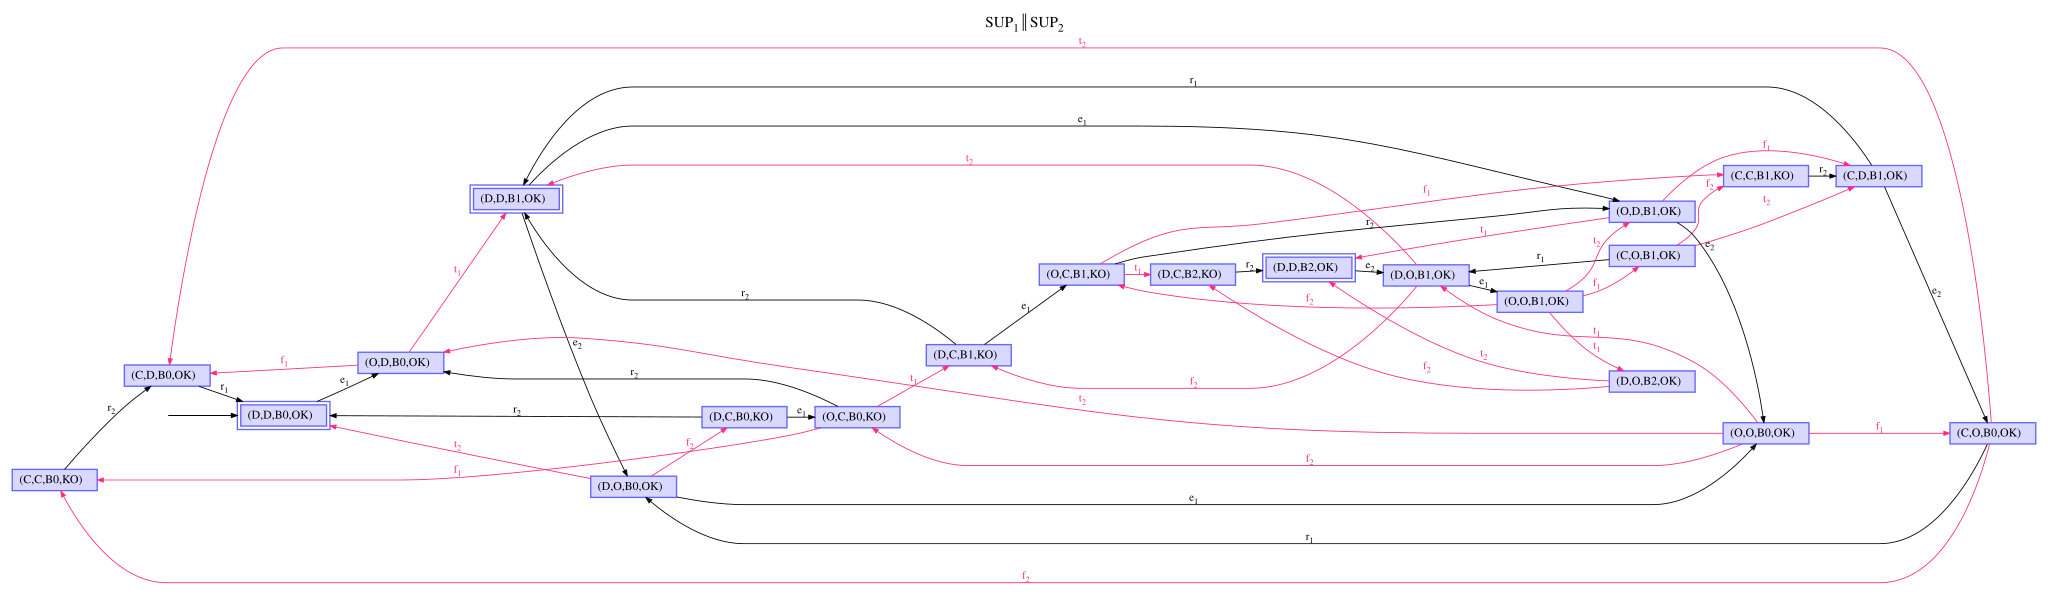

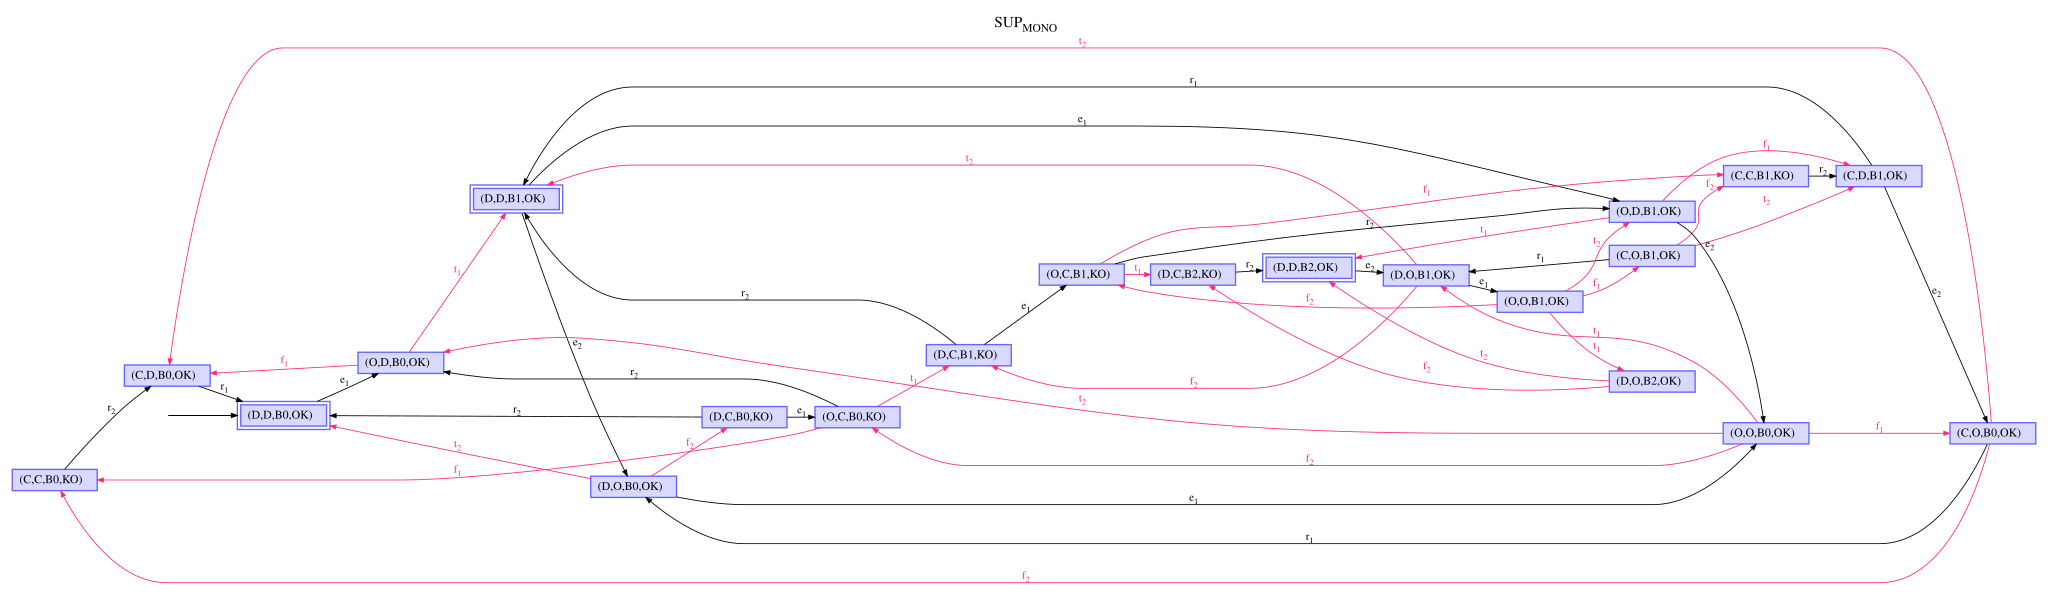

In [10]:
ALL = allevents(G)
print('¿SUP1 y SUP2 son no conflictivos?', nonconflict(SUP1_SUP2, ALL))
print('estados bloqueantes:', sorted(SUP1_SUP2.X - coac(SUP1_SUP2).X))
draw(SUP1_SUP2, SUP_MONO)